Code to prove reducibility

In [1]:
import copy
import itertools
import geogebra_graph

In [2]:
#!/usr/bin/env python

def does_extend(G, coloring, num_colors):
    p = MixedIntegerLinearProgram()
    x= p.new_variable(binary=True)
    L= G.line_graph()
    for e in G.edges(): 
        p.add_constraint(p.sum(x[e,i] for i in range(num_colors)) == 1) #every edge must have one color
    
    for e,f in L.edges(labels=False):
        for i in range(num_colors):
            p.add_constraint(x[e,i] + x[f,i] <=1) #adjacent edges must have different colors
    
    for e in G.edges():
        if e[2]: #is not none
            tuple_index,color_index = e[2]
            p.add_constraint(x[e, coloring[tuple_index][color_index] ] == 1) #considers the established coloring of the half-edges
    
    p.set_objective(0)
    try:
        p.solve()
        return True
    except sage.numerical.mip.MIPSolverException:
        #print(coloring)
        return False
    
def test_colorings(degrees, Graph, num_colors=6):
    
    C=list(range(num_colors))  # list of colors, for convenience
    
    S=set()  # the set of colorings that can be modified to an extendible coloring
    U=set()
    for coloring in itertools.product(
        *(
          (tuple(x) for x in itertools.combinations(C,d))
          for d in degrees
         )
        ):
        if does_extend(Graph, coloring, num_colors):  #extend conditions
            S.add(coloring)
        else:
            U.add(coloring)
        #print(coloring)
    print(len(S), len(U))
    return S,U

In [3]:
S1 = set() #list that does work after one change
U1 = set() #list that don't work

def perform_Kempe(coloring, i, j, S):
    aux_edges = list()
    vertex_index = set()
    degree_two_vertices = set()
    
    # for trailing off Kempe Chains or loops in auxillary graph
    for k in range(len(coloring)):
        coloring_vertex = copy.deepcopy(list(coloring[k]))
        isChanged = 0
        for l in range(len(coloring_vertex)):
            test_coloring = copy.deepcopy(coloring)
            if coloring_vertex[l] == i:
                coloring_vertex[l] =j
                isChanged += 1
            else:
                if coloring_vertex[l] == j:
                    coloring_vertex[l]=i
                    isChanged += 1
        coloring_vertex.sort()
        if isChanged==1:
            test_coloring[k] = tuple(coloring_vertex)
            test_coloring = tuple(test_coloring)
            if test_coloring in S:
                S1.add(test_coloring)
            else:
                U1.add(test_coloring)
                aux_edges.append(tuple((k,)))
        if isChanged==2:
            test_coloring[k] = tuple(coloring_vertex)
            test_coloring = tuple(test_coloring)
            U1.add(test_coloring)
            aux_edges.append(tuple((k,)))
            
    #gets the set of vertices that contains the colors i and j and the "half-edge degree" it has
    for k in range(len(coloring)):
        color_index=set()
        degree =0
        for l in range(len(coloring[k])):
            if coloring[k][l] == i:
                color_index.add(l)
                degree+=1
            if coloring[k][l] == j:
                color_index.add(l)
                degree+=1
        if color_index != set():
            vertex_index.add(k)
            if degree == 2:
                degree_two_vertices.add(k)

    #testing the Kempe Chains to see if it extends (multiple vertices)
    for endpoints in itertools.combinations(vertex_index, 2):
        testing_vertex_index = copy.deepcopy(vertex_index)
        start = endpoints[0]
        end = endpoints[1]
        test_coloring = copy.deepcopy(coloring)
        coloring_s = copy.deepcopy(list(coloring[start]))
        coloring_e = copy.deepcopy(list(coloring[end]))
        for m in range(len(coloring_s)):
            if coloring_s[m] == i:
                coloring_s[m] =j
            else:
                if coloring_s[m] == j:
                    coloring_s[m]= i
        coloring_s.sort()
        for m in range(len(coloring_e)):
            if coloring_e[m] == i:
                coloring_e[m] =j
            else:
                if coloring_e[m] == j:
                    coloring_e[m]= i
        coloring_e.sort()
        test_coloring[start] = tuple(coloring_s)
        test_coloring[end] = tuple(coloring_e)
        testing_vertex_index.remove(endpoints[0])
        testing_vertex_index.remove(endpoints[1])
        
        if tuple(test_coloring) in S:
            S1.add(tuple(test_coloring))
        else:
            for middle in powerset(degree_two_vertices-set(endpoints)):
                kempe = set(middle) | set(endpoints)
                kempe= tuple(sorted(kempe))
                U1.add(tuple(test_coloring))
                aux_edges.append(kempe)
    return vertex_index, aux_edges

In [4]:
#just testing their intersection (if the edges are intersecting then just return False as the case will be dealt with in the MIP)
def check_Crossing(edge1, edge2): 
    is_crossing = True
    if len(edge1) == 1 or len(edge2)==1: #trailing off Kempe chains are not crossing
        is_crossing = False
    else:
        minimum = min(edge1[0], edge2[0]) #edges of Kempe are in order so just need to test the 1st values for the min
        if minimum in edge1:
            start_edge = edge1
            test_edge = set(edge2)
        else:
            start_edge = edge2
            test_edge = set(edge1)
        maximum = max(max(test_edge), max(start_edge))
        start_edge = start_edge + (maximum,)
        #print(f'{start_edge=}, {test_edge=}, {maximum=}')
        for k in range(len(start_edge)-1):
            test_range = set(range(start_edge[k], start_edge[k+1]+1))
            intersection = test_range & test_edge
            #print(f'{k=}, {test_range=}, {intersection=}')
            if intersection == test_edge:
                is_crossing = False
            
    return is_crossing

In [5]:
#returns true if there is a matching found and false if not
def check_Matching(aux_vertices, aux_edges):
    if not aux_vertices: #if empty
        return True
    p = MixedIntegerLinearProgram()
    x= p.new_variable(binary=True)
    matching = set()

    #if len(aux_edges) != 0 or len(aux_edges) != 1:
        #for i in range(len(aux_edges)):
            #for j in range(i):
                #crossing = check_Crossing(aux_edges[i], aux_edges[j]) #check crossing
                #if crossing == True:
                    #print(f'crossing between {aux_edges[i]} and {aux_edges[j]}')
                    #p.add_constraint(x[i]+x[j] <= 1)
    for i,j in itertools.combinations(range(len(aux_edges)),2):
        if check_Crossing(aux_edges[i], aux_edges[j]) == True:
            #print(f'crossing between {aux_edges[i]} and {aux_edges[j]}')
            p.add_constraint(x[i]+x[j] <= 1)
                    
    #constraints to make sure all vertices are covered
    for v in aux_vertices:
        adj_edges = list()
        for j in range(len(aux_edges)):
            if v in aux_edges[j]:
                adj_edges.append(j)
        if adj_edges:  #non-empty
            p.add_constraint(p.sum(x[j] for j in adj_edges) ==1)
        else: #if adj_edges is empty then there is no edges in aux that contain v and so no perfect matching
            return False
            
    p.set_objective(0)
    try:
        p.solve()
        return True
    except sage.numerical.mip.MIPSolverException: #check to make sure exceptions thrown are infeasible and not anything else
        return False

In [6]:
def test_all_colors(coloring, S, num_colors=6):
    CL = copy.deepcopy(list(coloring))
    for i in range(num_colors):
        for j in range(num_colors):
            if i < j:
                aux_vertices, aux_edges= perform_Kempe(CL, i, j, S)
                #x = perform_Kempe(CL, i, j)
                #print(f'{aux}')
                #print(f'{aux_vertices=},{aux_edges=} for {i} and {j}')
                matching = check_Matching(aux_vertices,aux_edges)
                if matching == False:
                    #print(f'No non-crossing perfect matching found for colors {i} and {j}')
                    return False
                    #print(f'Found a non-crossing perfect matching auxilliary for colors {i} and {j}')
                #else:
    return True

In [7]:
def test_reducibility(S,U):
    while True:
        print(f'Starting while loop, {len(U)=}')
        remove_from_U = set()
        for coloring in U:
            if test_all_colors(coloring, S) == False:
                S.add(coloring)
                remove_from_U.add(coloring)
        if remove_from_U: #non-empty
            U = U - remove_from_U
            if not U: #U is empty
                print(f'U is empty, therefore it is reducible. YAY!')
                break
        else:
            print(f'Nothing removed from U, {len(U)=}')
            break
        #print(UL[i])
        #print(test_all_colors(UL[i]))
    return S,U

In [8]:
def find_equiv_classes(UL):
    equivalence_classes=[]
    for colornum,coloring in enumerate(UL):
        #print(f"{colornum=} {coloring=}")
        for orbit in equivalence_classes:
            if coloring in orbit:
                break
        else:
            print(f"Adding a new class, {len(equivalence_classes)=}, {coloring=}")
            orbit=set()          
            for i,pi in enumerate(itertools.permutations(range(6))):
                image=tuple(
                       tuple(sorted([pi[z] for z in x]))
                       for x in coloring)
                orbit.add(image)
                # if image not in U:
                #     print(f"{pi=}",type(pi))
                #     print(f"{image=}", image in U)
                #if i>3: break
            equivalence_classes.append(orbit)

In [9]:
def is_config_reducible(G):
    #relabeling graph edges from the geogebra file
    half_edge_color = (0,0,255,0.0)
    half_edges = [e for e in G.edges() if e[2]["color"] == half_edge_color]
    for e in G.edges():
        G.set_edge_label(e[0],e[1],None) #erasing all the information from Geogebra
        
    end_points_half_edges = list(set(sum([list(e[:2]) 
        for e in half_edges],[])))
    config_vertices = [v for v in end_points_half_edges if G.degree(v) > 1]
    pos = G.get_pos()
    angle_config_vertices = sorted([(atan2(pos[v][1], pos[v][0]),v) for v in config_vertices])
    cyclic_vertices = [x[1] for x in angle_config_vertices]
    degrees = [-1] * len(cyclic_vertices)
    for i,v in enumerate(cyclic_vertices):
        half_edges_at_v = [e for e in half_edges if v in e]
        degrees[i] = len(half_edges_at_v)
        for j,e in enumerate(half_edges_at_v):
            G.set_edge_label(*(e[:2]), (i,j))
            
    print(G.edges())
    G.show(edge_labels = True)
    S,U = test_colorings(degrees,G) #need to not hard code
    S,U=test_reducibility(S,U)
    if U: #non-empty
        UL = sorted(list(U))
        find_equiv_classes(UL)
    else:
        print("YAY! It's reducible")

Testing Configurations

[(0, 1, None), (0, 3, None), (0, 4, (2, 0)), (1, 2, None), (1, 3, None), (1, 9, (3, 0)), (1, 10, (3, 1)), (1, 11, (3, 2)), (2, 3, None), (2, 8, (0, 0)), (3, 5, (1, 0)), (3, 6, (1, 1)), (3, 7, (1, 2))]


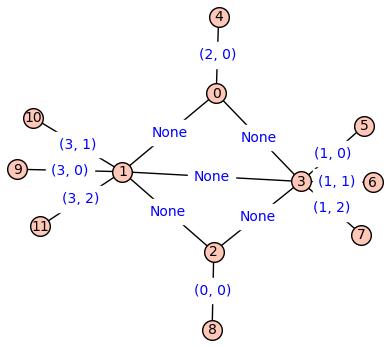

12120 2280
Starting while loop, len(U)=2280
Starting while loop, len(U)=720
Nothing removed from U, len(U)=720
Adding a new class, len(equivalence_classes)=0, coloring=((0,), (0, 1, 2), (0,), (3, 4, 5))
Adding a new class, len(equivalence_classes)=1, coloring=((0,), (0, 1, 2), (1,), (3, 4, 5))
Adding a new class, len(equivalence_classes)=2, coloring=((0,), (0, 1, 2), (3,), (3, 4, 5))
Adding a new class, len(equivalence_classes)=3, coloring=((0,), (1, 2, 3), (0,), (0, 4, 5))
Adding a new class, len(equivalence_classes)=4, coloring=((0,), (1, 2, 3), (1,), (0, 4, 5))
Adding a new class, len(equivalence_classes)=5, coloring=((0,), (1, 2, 3), (4,), (0, 4, 5))


In [10]:
is_config_reducible(geogebra_graph.geogebra_to_graph("chordal4cycle.ggb"))

[(0, 1, None), (0, 3, None), (0, 4, (2, 0)), (0, 5, (2, 1)), (1, 2, None), (1, 3, None), (1, 11, (3, 0)), (1, 12, (3, 1)), (1, 13, (3, 2)), (2, 3, None), (2, 9, (0, 0)), (2, 10, (0, 1)), (3, 6, (1, 0)), (3, 7, (1, 1)), (3, 8, (1, 2))]


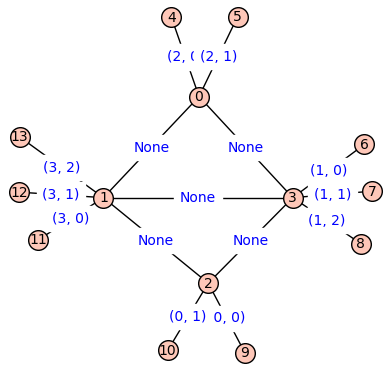

41040 48960
Starting while loop, len(U)=48960
Starting while loop, len(U)=13553
Starting while loop, len(U)=12240
Nothing removed from U, len(U)=12240
Adding a new class, len(equivalence_classes)=0, coloring=((0, 1), (0, 1, 2), (0, 1), (3, 4, 5))
Adding a new class, len(equivalence_classes)=1, coloring=((0, 1), (0, 1, 2), (0, 2), (3, 4, 5))
Adding a new class, len(equivalence_classes)=2, coloring=((0, 1), (0, 1, 2), (0, 3), (1, 2, 3))
Adding a new class, len(equivalence_classes)=3, coloring=((0, 1), (0, 1, 2), (0, 3), (1, 4, 5))
Adding a new class, len(equivalence_classes)=4, coloring=((0, 1), (0, 1, 2), (0, 3), (3, 4, 5))
Adding a new class, len(equivalence_classes)=5, coloring=((0, 1), (0, 1, 2), (2, 3), (0, 1, 3))
Adding a new class, len(equivalence_classes)=6, coloring=((0, 1), (0, 1, 2), (2, 3), (3, 4, 5))
Adding a new class, len(equivalence_classes)=7, coloring=((0, 1), (0, 1, 2), (3, 4), (0, 1, 5))
Adding a new class, len(equivalence_classes)=8, coloring=((0, 1), (0, 1, 2), (3, 

In [11]:
is_config_reducible(geogebra_graph.geogebra_to_graph("chordal4cycle2.ggb"))

[(0, 1, None), (0, 2, None), (0, 4, None), (0, 5, (2, 0)), (0, 6, (2, 1)), (1, 2, None), (1, 9, (3, 0)), (2, 3, None), (2, 7, (4, 0)), (2, 8, (4, 1)), (3, 4, None), (3, 11, (0, 0)), (4, 10, (1, 0))]


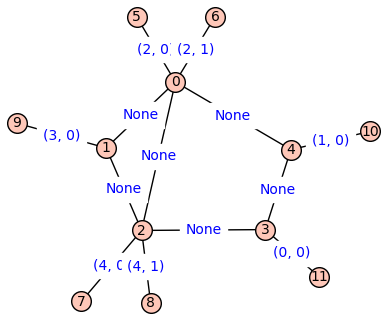

48600 0
Starting while loop, len(U)=0
Nothing removed from U, len(U)=0
YAY! It's reducible


In [13]:
is_config_reducible(geogebra_graph.geogebra_to_graph("chordal5cycle.ggb"))

[(0, 1, None), (0, 5, None), (0, 12, (4, 0)), (1, 2, None), (1, 5, None), (1, 9, (3, 0)), (1, 10, (3, 1)), (1, 11, (3, 2)), (2, 3, None), (2, 15, (2, 0)), (3, 4, None), (3, 14, (1, 0)), (4, 5, None), (4, 13, (0, 0)), (5, 6, (5, 0)), (5, 7, (5, 1)), (5, 8, (5, 2))]


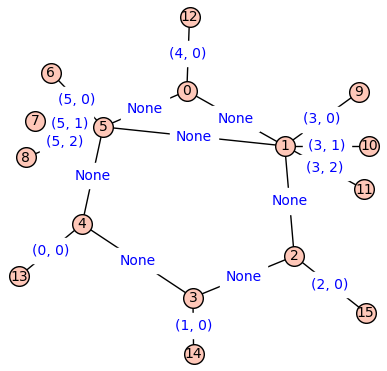

452880 65520
Starting while loop, len(U)=65520
Starting while loop, len(U)=25920
Nothing removed from U, len(U)=25920
Adding a new class, len(equivalence_classes)=0, coloring=((0,), (0,), (0,), (0, 1, 2), (0,), (3, 4, 5))
Adding a new class, len(equivalence_classes)=1, coloring=((0,), (0,), (0,), (0, 1, 2), (1,), (3, 4, 5))
Adding a new class, len(equivalence_classes)=2, coloring=((0,), (0,), (0,), (0, 1, 2), (3,), (3, 4, 5))
Adding a new class, len(equivalence_classes)=3, coloring=((0,), (0,), (0,), (1, 2, 3), (0,), (0, 4, 5))
Adding a new class, len(equivalence_classes)=4, coloring=((0,), (0,), (0,), (1, 2, 3), (1,), (0, 4, 5))
Adding a new class, len(equivalence_classes)=5, coloring=((0,), (0,), (0,), (1, 2, 3), (4,), (0, 4, 5))
Adding a new class, len(equivalence_classes)=6, coloring=((0,), (0,), (1,), (0, 1, 2), (0,), (3, 4, 5))
Adding a new class, len(equivalence_classes)=7, coloring=((0,), (0,), (1,), (0, 1, 2), (1,), (3, 4, 5))
Adding a new class, len(equivalence_classes)=8, co

In [14]:
is_config_reducible(geogebra_graph.geogebra_to_graph("chordal6cycle3loop.ggb"))

[(0, 1, None), (0, 5, None), (0, 12, (4, 0)), (1, 2, None), (1, 4, None), (1, 9, (3, 0)), (1, 10, (3, 1)), (1, 11, (3, 2)), (2, 3, None), (2, 15, (2, 0)), (3, 4, None), (3, 14, (1, 0)), (4, 5, None), (4, 13, (0, 0)), (5, 6, (5, 0)), (5, 7, (5, 1)), (5, 8, (5, 2))]


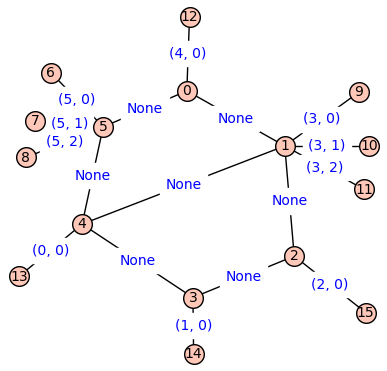

511200 7200
Starting while loop, len(U)=7200
U is empty, therefore it is reducible. YAY!
YAY! It's reducible


In [15]:
is_config_reducible(geogebra_graph.geogebra_to_graph("chordal6cycle4loop.ggb"))

[(0, 1, None), (0, 2, None), (0, 3, (2, 0)), (0, 4, (2, 1)), (0, 13, (2, 2)), (0, 14, (2, 3)), (1, 2, None), (1, 7, (1, 0)), (1, 8, (1, 1)), (1, 9, (1, 2)), (1, 10, (1, 3)), (2, 5, (0, 0)), (2, 6, (0, 1)), (2, 11, (0, 2)), (2, 12, (0, 3))]


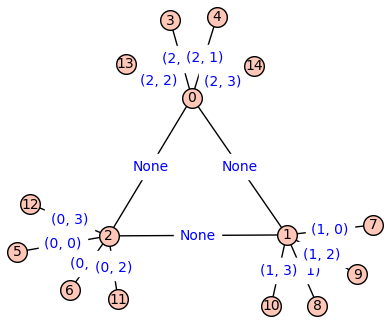

120 3255
Starting while loop, len(U)=3255
Nothing removed from U, len(U)=3255
Adding a new class, len(equivalence_classes)=0, coloring=((0, 1, 2, 3), (0, 1, 2, 3), (0, 1, 2, 3))
Adding a new class, len(equivalence_classes)=1, coloring=((0, 1, 2, 3), (0, 1, 2, 3), (0, 1, 2, 4))
Adding a new class, len(equivalence_classes)=2, coloring=((0, 1, 2, 3), (0, 1, 2, 3), (0, 1, 4, 5))
Adding a new class, len(equivalence_classes)=3, coloring=((0, 1, 2, 3), (0, 1, 2, 4), (0, 1, 2, 3))
Adding a new class, len(equivalence_classes)=4, coloring=((0, 1, 2, 3), (0, 1, 2, 4), (0, 1, 2, 4))
Adding a new class, len(equivalence_classes)=5, coloring=((0, 1, 2, 3), (0, 1, 2, 4), (0, 1, 3, 4))
Adding a new class, len(equivalence_classes)=6, coloring=((0, 1, 2, 3), (0, 1, 2, 4), (0, 1, 3, 5))
Adding a new class, len(equivalence_classes)=7, coloring=((0, 1, 2, 3), (0, 1, 2, 4), (0, 1, 4, 5))
Adding a new class, len(equivalence_classes)=8, coloring=((0, 1, 2, 3), (0, 1, 2, 4), (0, 3, 4, 5))
Adding a new class, le

In [16]:
is_config_reducible(geogebra_graph.geogebra_to_graph("3cycle_allmaxdegree.ggb"))

[(0, 1, None), (0, 3, None), (0, 5, None), (0, 7, (3, 0)), (0, 8, (3, 1)), (0, 9, (3, 2)), (1, 2, None), (1, 14, (2, 0)), (2, 3, None), (2, 15, (1, 0)), (3, 4, None), (3, 10, (0, 0)), (3, 11, (0, 1)), (3, 12, (0, 2)), (4, 5, None), (4, 13, (5, 0)), (5, 6, (4, 0))]


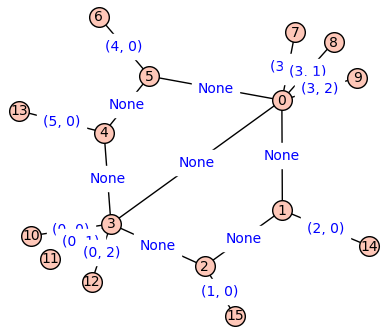

454020 64380
Starting while loop, len(U)=64380
Starting while loop, len(U)=25920
Nothing removed from U, len(U)=25920
Adding a new class, len(equivalence_classes)=0, coloring=((0, 1, 2), (0,), (0,), (3, 4, 5), (0,), (0,))
Adding a new class, len(equivalence_classes)=1, coloring=((0, 1, 2), (0,), (0,), (3, 4, 5), (0,), (1,))
Adding a new class, len(equivalence_classes)=2, coloring=((0, 1, 2), (0,), (0,), (3, 4, 5), (0,), (3,))
Adding a new class, len(equivalence_classes)=3, coloring=((0, 1, 2), (0,), (0,), (3, 4, 5), (1,), (0,))
Adding a new class, len(equivalence_classes)=4, coloring=((0, 1, 2), (0,), (0,), (3, 4, 5), (1,), (1,))
Adding a new class, len(equivalence_classes)=5, coloring=((0, 1, 2), (0,), (0,), (3, 4, 5), (1,), (2,))
Adding a new class, len(equivalence_classes)=6, coloring=((0, 1, 2), (0,), (0,), (3, 4, 5), (1,), (3,))
Adding a new class, len(equivalence_classes)=7, coloring=((0, 1, 2), (0,), (0,), (3, 4, 5), (3,), (0,))
Adding a new class, len(equivalence_classes)=8, co

In [17]:
is_config_reducible(geogebra_graph.geogebra_to_graph("chordal6cycle4loop2.ggb"))

[(0, 1, None), (0, 3, None), (0, 5, None), (0, 7, (3, 0)), (0, 8, (3, 1)), (1, 2, None), (1, 12, (2, 0)), (2, 3, None), (2, 13, (1, 0)), (3, 4, None), (3, 9, (0, 0)), (3, 10, (0, 1)), (4, 5, None), (4, 11, (5, 0)), (5, 6, (4, 0))]


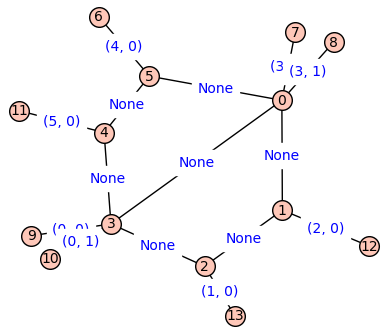

291600 0
Starting while loop, len(U)=0
Nothing removed from U, len(U)=0
YAY! It's reducible


In [18]:
is_config_reducible(geogebra_graph.geogebra_to_graph("chordal6cycle4loop3.ggb"))

[(0, 1, None), (0, 3, None), (0, 5, None), (0, 7, (3, 0)), (0, 8, (3, 1)), (1, 2, None), (1, 12, (2, 0)), (2, 3, None), (2, 13, (1, 0)), (3, 4, None), (3, 9, (0, 0)), (3, 10, (0, 1)), (3, 14, (0, 2)), (4, 5, None), (4, 11, (5, 0)), (5, 6, (4, 0))]


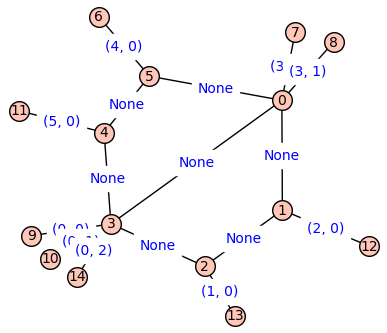

378000 10800
Starting while loop, len(U)=10800
U is empty, therefore it is reducible. YAY!
YAY! It's reducible


In [20]:
is_config_reducible(geogebra_graph.geogebra_to_graph("chordal6cycle4loop4.ggb"))

[(0, 1, None), (0, 3, None), (0, 5, None), (0, 7, (3, 0)), (0, 8, (3, 1)), (1, 2, None), (1, 18, (2, 0)), (1, 12, (2, 1)), (2, 17, (1, 0)), (2, 3, None), (2, 13, (1, 1)), (3, 4, None), (3, 9, (0, 0)), (3, 10, (0, 1)), (3, 14, (0, 2)), (4, 16, (5, 0)), (4, 5, None), (4, 11, (5, 1)), (5, 6, (4, 0)), (5, 15, (4, 1))]


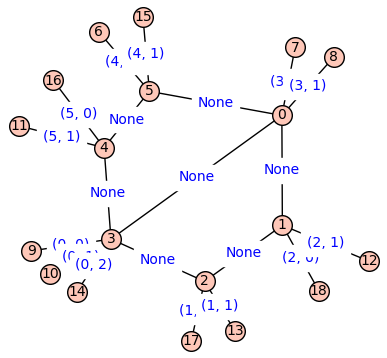

12956580 2230920
Starting while loop, len(U)=2230920
Starting while loop, len(U)=5645
U is empty, therefore it is reducible. YAY!
YAY! It's reducible


In [21]:
is_config_reducible(geogebra_graph.geogebra_to_graph("chordal6cycle4loop5.ggb"))